# Experiment 01 — SciConv per-turn output tokens

Original Astra-low traces, 40 cases × 6 settings × 3 trials. Actor, simulator and judge calls remain separate. No API calls. Run in Python with NumPy/Matplotlib; the frozen numeric snapshot omits private prompt/reply text.

[Plan](PLAN.md) · [Report](SCICONV_TOKENS.md)

In [1]:
from pathlib import Path
import sys, importlib.util, inspect, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Experiment/01_behavioral_diversity/code/analyze_sciconv_tokens.py').exists())
BASE = ROOT / 'Experiment/01_behavioral_diversity'
sys.path.insert(0, str(BASE / 'code'))
import analyze_sciconv_tokens as analysis
import plot_sciconv_tokens as plotting
snapshot = json.loads((BASE / 'data/sciconv_tokens/snapshot.json').read_text())
print('Episode slots:', len(snapshot['episodes']))
print('Successful API records:', len(snapshot['calls']))


Episode slots: 720
Successful API records: 7751


## Data definition and turn alignment

`output_tokens` is API completion_tokens including reasoning; non-reasoning output subtracts reasoning only when available. Input tokens include prompt/history and are not output. Raw API record order supplies role-local call numbers. Actor questions pair with same-numbered simulator replies; the last actor call is the final specification. Judge calls are not interaction turns. Failed API requests have no successful usage record and are not counted as zero-cost answers.

The extraction code is shown below for review; this notebook uses the saved numeric snapshot rather than reading private content again.

In [2]:
print(inspect.getsource(analysis.extract))


def extract(item):
 trial,row=item;n=next((x for x in row.get('native_results',[]) if x.get('benchmark')=='sciconvbench'),{});mode=row['task_id'].split('/')[1]
 meta={'trial':trial,'case':row['task_id'],'mode':mode,'study_id':row.get('study_id') or row['task_id'],'arm':row['arm'],'status':row['status'],'attempt':row.get('attempt')}
 if row['status']!='finished' or n.get('status')!='scored':return meta,[],None
 path=Path(n['case_directory'])/'controller/api_calls.private.jsonl'
 if not path.exists():return {**meta,'status':'trace_missing'},[],None
 raw=path.read_bytes();counts=Counter();calls=[]
 for index,line in enumerate(raw.splitlines()):
  c=json.loads(line);role=c['role'];counts[role]+=1;u=c.get('usage') or {};total=u.get('completion_tokens');reason=(u.get('completion_tokens_details') or {}).get('reasoning_tokens')
  if total is not None:assert isinstance(total,int) and total>=0
  if reason is not None:assert isinstance(reason,int) and 0<=reason<=total
  calls.append({**meta,'call

## Aggregation and uncertainty

Average output across calls within an episode, trials within a case, then cases equally. Retain per-episode total output as a separate metric. Study-cluster bootstrap within disambiguation/inconsistency mode: 20,000 draws, seed 20261003. Pointwise intervals condition on observed trials, not independent repeat-run uncertainty; no corrected significance claim.
Episodes without simulator replies contribute zero to episode totals but no per-reply value. Per-reply means are conditional on at least one reply; their smaller denominators are explicit.


In [3]:
print(inspect.getsource(analysis.cluster_summary))
summary = analysis.analyze(snapshot)
print(analysis.table(summary))


def cluster_summary(rows,field,rng):
 # An episode contributes one value; trials average within case before aggregation.
 grouped=defaultdict(list)
 for r in rows:
  if r.get(field) is not None:grouped[(r['case'],r['mode'],r['study_id'])].append(r[field])
 cases=[dict(case=k[0],mode=k[1],study_id=k[2],value=float(np.mean(v))) for k,v in sorted(grouped.items())]
 if not cases:return {'mean':None,'ci95':None,'cases':0,'episodes':0}
 boot=np.zeros(B)
 for mode in sorted({x['mode'] for x in cases}):
  sub=[x for x in cases if x['mode']==mode];clusters=sorted({x['study_id'] for x in sub})
  sums=np.array([sum(x['value'] for x in sub if x['study_id']==c) for c in clusters]);counts=np.array([sum(x['study_id']==c for x in sub) for c in clusters]);w=rng.multinomial(len(clusters),np.ones(len(clusters))/len(clusters),size=B)
  boot+=(w@sums)/(w@counts)*len(sub)/len(cases)
 return {'mean':float(np.mean([x['value'] for x in cases])),'ci95':np.quantile(boot,[.025,.975]).tolist(),'cases':len(cases),'

## Reasoning versus non-reasoning output

The following table separates the total API output from its reported reasoning component. Non-reasoning counts are not language-normalized information content.

In [4]:
for arm,label in zip(analysis.ARMS,analysis.LABELS):
    for role in ['actor','researcher']:
        s=summary['roles'][role][arm]
        print(label, role, {metric: round(s[metric]['mean'], 1) for metric in ['output_tokens_per_call','reasoning_tokens_per_call','nonreasoning_output_tokens_per_call']})


Off actor {'output_tokens_per_call': 160.0, 'reasoning_tokens_per_call': 11.7, 'nonreasoning_output_tokens_per_call': 148.3}
Off researcher {'output_tokens_per_call': 73.9, 'reasoning_tokens_per_call': 0.1, 'nonreasoning_output_tokens_per_call': 73.8}
148 actor {'output_tokens_per_call': 167.3, 'reasoning_tokens_per_call': 11.0, 'nonreasoning_output_tokens_per_call': 156.3}
148 researcher {'output_tokens_per_call': 90.4, 'reasoning_tokens_per_call': 0.0, 'nonreasoning_output_tokens_per_call': 90.4}
155 actor {'output_tokens_per_call': 188.7, 'reasoning_tokens_per_call': 10.6, 'nonreasoning_output_tokens_per_call': 178.2}
155 researcher {'output_tokens_per_call': 113.8, 'reasoning_tokens_per_call': 0.1, 'nonreasoning_output_tokens_per_call': 113.8}
089 actor {'output_tokens_per_call': 148.6, 'reasoning_tokens_per_call': 11.3, 'nonreasoning_output_tokens_per_call': 137.3}
089 researcher {'output_tokens_per_call': 64.7, 'reasoning_tokens_per_call': 0.0, 'nonreasoning_output_tokens_per_cal

## Per-turn trajectories

All turn-level estimates and CIs are exported to `data/sciconv_tokens/per_turn_tokens.csv`. Later turns contain only episodes that reached them; changing denominators prevent a simple within-episode growth interpretation. Actor call-number groups may mix questions and final specifications; the export records how many are final calls.

In [5]:
import csv
turns=list(csv.DictReader((BASE/'data/sciconv_tokens/per_turn_tokens.csv').open()))
for row in turns:
    if row['role']=='researcher':
        print(row['persona'], 'turn', row['turn'], 'output', row['mean'], 'episodes', row['episodes'])


persona_off turn 1 output 80.73684210526316 episodes 112
persona_off turn 2 output 67.96296296296296 episodes 72
persona_off turn 3 output 57.48484848484849 episodes 58
persona_off turn 4 output 57.35 episodes 50
persona_off turn 5 output 71.08333333333334 episodes 35
persona_off turn 6 output 79.43589743589745 episodes 29
persona_off turn 7 output 70.73333333333332 episodes 22
persona_off turn 8 output 60.333333333333336 episodes 16
persona_off turn 9 output 71.0 episodes 15
persona_off turn 10 output 75.5 episodes 12
candidate_148 turn 1 output 97.14912280701755 episodes 112
candidate_148 turn 2 output 73.50000000000001 episodes 69
candidate_148 turn 3 output 80.21212121212122 episodes 60
candidate_148 turn 4 output 73.86842105263158 episodes 45
candidate_148 turn 5 output 91.52222222222223 episodes 34
candidate_148 turn 6 output 95.5909090909091 episodes 23
candidate_148 turn 7 output 98.04761904761905 episodes 15
candidate_148 turn 8 output 96.7 episodes 12
candidate_148 turn 9 out

## Manuscript figure

Role-specific per-call output with numeric pointwise 95% CIs, all six settings, and case/episode denominators. Actor means include final specifications; question-only and final-output statistics are available in the JSON summary. Figure follows the Python nature-figure workflow; alignment is checked before export, and PDF collision/text audits are stored alongside the exports.

def plot(summary,show=False):
    plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['DejaVu Sans'],
        'font.size':7,'axes.labelsize':7,'axes.titlesize':8,'xtick.labelsize':6.5,'ytick.labelsize':6.5,
        'axes.spines.top':False,'axes.spines.right':False,'axes.linewidth':0.6,
        'xtick.major.width':0.6,'ytick.major.width':0.6,'xtick.major.size':2.5,'ytick.major.size':2.5,
        'pdf.fonttype':42,'svg.fonttype':'none','legend.frameon':False})
    p=summary['roles']
    fig,axes=plt.subplots(1,2,figsize=(7.2047244094,3.9370078740))
    fig.subplots_adjust(left=.085,right=.985,bottom=.255,top=.81,wspace=.28)
    rows=[]
    specs=[(axes[0],ARMS,LABELS,[p['actor'][a]['output_tokens_per_call'] for a in ARMS],'Actor output','Output tokens per call'),
           (axes[1],ARMS,LABELS,[p['researcher'][a]['output_tokens_per_call'] for a in ARMS],'Simulator output','Output tokens per reply')]
    for letter,(ax,arms,labels,stats,title,ylabel) in zip(['a','b'],specs

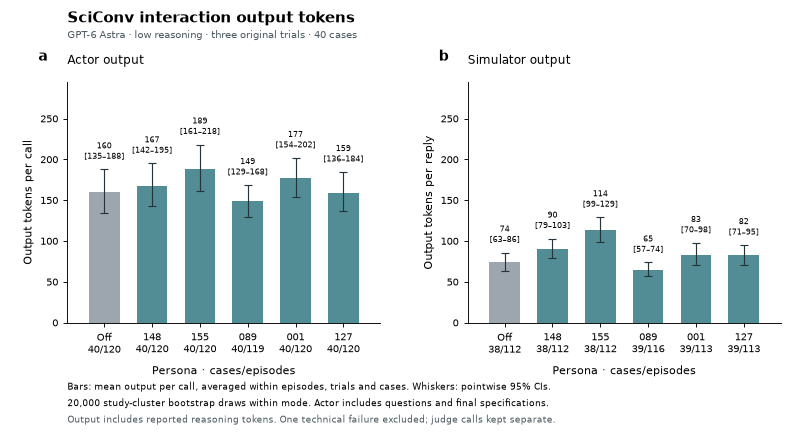

In [6]:
print(inspect.getsource(plotting.plot))
fig = plotting.plot(summary, show=True)


## Validation and saved artifacts

In [7]:
from collections import Counter,defaultdict
assert len(snapshot['episodes'])==720
assert Counter(e['status'] for e in snapshot['episodes'])=={'scored':719,'infrastructure_error':1}
assert len({(r['trial'],r['case'],r['arm'],r['call_index']) for r in snapshot['calls']})==len(snapshot['calls'])
assert all(r['output_tokens']>=r['reasoning_tokens']>=0 for r in snapshot['calls'])
assert all(r['nonreasoning_output_tokens']==r['output_tokens']-r['reasoning_tokens'] for r in snapshot['calls'])
for role, arms in summary['roles'].items():
    for arm, metrics in arms.items():
        s=metrics['output_tokens_per_call']
        assert 0 < s['cases'] <= 40 and 0 < s['episodes'] <= 120
        t=metrics['output_tokens_total']
        assert t['cases']==40 and t['episodes'] in (119,120)
        assert s['ci95'][0]<=s['mean']<=s['ci95'][1]
analysis.report(summary)
print('Validated coverage, unique calls, usage arithmetic, case/episode denominators and CI bounds.')
print('Report: SCICONV_TOKENS.md')


Validated coverage, unique calls, usage arithmetic, case/episode denominators and CI bounds.
Report: SCICONV_TOKENS.md


## Scope and interpretation

This completes the output-token component of Experiment 01, not every behavioral or semantic-analysis objective in its plan. Original trials only; repairs, Sol and the exhausted-credit baseline remain separate. Persona 155 produces high token output despite low whitespace word counts; neither quantity directly measures fact disclosure.

[Call CSV](data/sciconv_tokens/calls.csv) · [Turn CSV](data/sciconv_tokens/per_turn_tokens.csv) · [Summary](data/sciconv_tokens/summary.json) · [PDF](figures/sciconv_tokens/output_tokens.pdf) · [SVG](figures/sciconv_tokens/output_tokens.svg)